In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS/'data'/'plata'
DATA_ADRESS = DATA_DIR/'viajes_foraneos_oro.csv'

# Cargar los datos
df = pd.read_csv(DATA_ADRESS)

# Verificar que exista la columna Placas
print("Columnas:", df.columns.tolist())
if 'Placas' in df.columns:
    print("\nEjemplo de datos:")
    print(df[['ID_VIAJE', 'Placas', 'PLANTA_ORIGEN', 'Ciudad Destino', 'FECHA_EGRESO', 'FECHA_VIAJE_FINALIZADO']].head())
    

Columnas: ['ID_VIAJE', 'Ciudad Destino', 'ID Camión', 'Tipo Camión', 'Programado (Peso)', 'PLANTA_ORIGEN', 'GRUPO_PLANTA_ORIGEN', 'FECHA_EGRESO', 'FAMILIA_CAMION_DESC', 'FECHA_VIAJE_FINALIZADO', 'Planta Origen', 'Transportista', 'Desc TpoTrn', 'Peso Total', 'Monto total', 'Placas', 'Tiempo_Viaje_Horas', 'Programado_kg', 'Discrepancia_Peso_kg', 'Ineficiencia_Capacidad', 'Nomenclatura_Inferida', 'Capacidad_Max_kg', 'Porcentaje_Utilizacion_Real', 'Capacidad_Sobra_kg', 'Toneladas_Reales', 'Toneladas_Maximas', 'Costo_Ton_Real', 'Costo_Ton_Optimo', 'Sobrecosto_Ton', 'Kilometros_Ruta', 'Tonelada_Kilometro', 'Costo_Ton_Km']

Ejemplo de datos:
   ID_VIAJE  Placas PLANTA_ORIGEN Ciudad Destino         FECHA_EGRESO  \
0  73520731  66AF7U      Guerrero      Tultitlán  2026-01-08 16:57:00   
1  73550402  748AG5      Guerrero    Guadalajara  2026-01-07 11:06:00   
2  73605053  99AL6N      Guerrero      Tultitlán  2026-01-09 17:33:00   
3  73621256  99AL6N      Guerrero      Tultitlán  2026-01-08 13:3

Viajes consolidados (misma placa, misma fecha, distinto destino): 0
Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): 4

Total de conexiones entre viajes analizadas: 53056
Estadísticas de horas de espera entre un viaje y otro de la misma placa:
count    53056.000000
mean        85.321981
std        281.865997
min       -214.555833
25%         -0.014722
50%         20.898750
75%         77.167847
max       5298.198889
Name: Horas_Espera_Nuevo_Viaje, dtype: float64
Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): 28005
Gráfica ciclos_placas.png generada.

Camión regresó y cargó de nuevo en la misma Planta de Origen: 54.4% de las veces


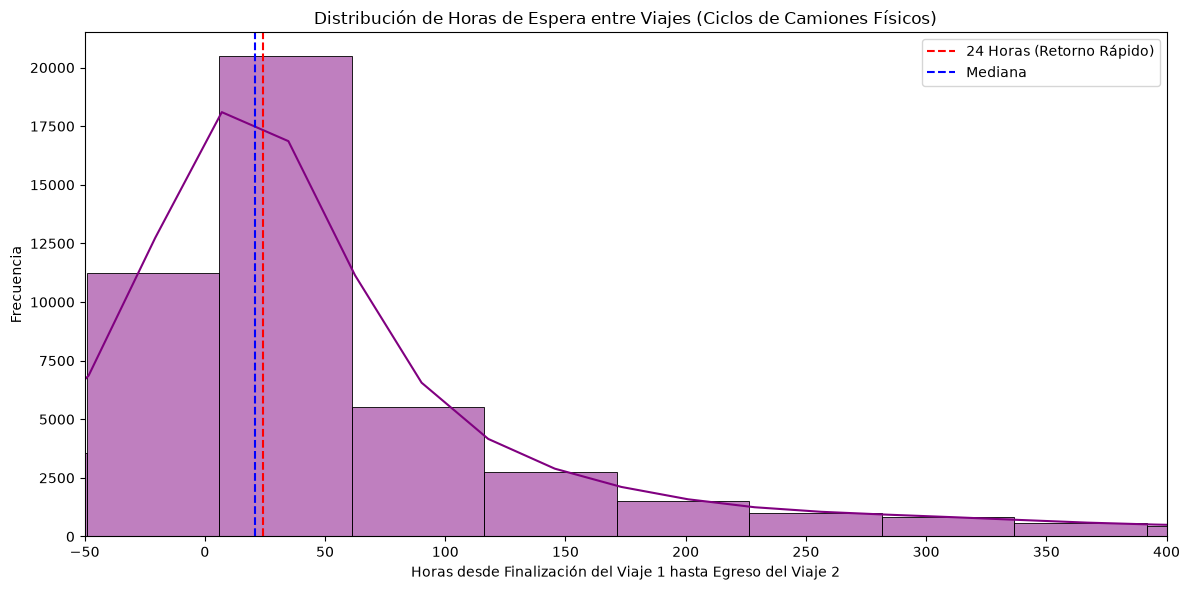

In [4]:
# Filtrar nulos en Placas
df = df.dropna(subset=['Placas']).copy()

# Convertir fechas
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['FECHA_VIAJE_FINALIZADO'] = pd.to_datetime(df['FECHA_VIAJE_FINALIZADO'])

# ANÁLISIS DE CONSOLIDACIÓN (Misma Placa, Misma Fecha, Distinto Destino)
# Agrupamos por Placa y Fecha de Egreso exacta (o podríamos usar ventana de 1 hr)
consolidacion = df.groupby(['Placas', 'FECHA_EGRESO']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Destinos_Lista=('Ciudad Destino', lambda x: list(set(x))),
    Total_Toneladas=('Toneladas_Reales', 'sum'),
    Capacidad_Max=('Capacidad_Max_kg', 'max') # Asumiendo misma placa = misma capacidad
).reset_index()

# Filtramos aquellos con >1 destino en el mismo minuto
consolidados_reales = consolidacion[consolidacion['Destinos_Unicos'] > 1]
print(f"Viajes consolidados (misma placa, misma fecha, distinto destino): {len(consolidados_reales)}")

if len(consolidados_reales) > 0:
    print(consolidados_reales.head(3))
    
# ¿Qué pasa si relajamos a "mismo día"?
df['Dia_Egreso'] = df['FECHA_EGRESO'].dt.date
cons_dia = df.groupby(['Placas', 'Dia_Egreso']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Toneladas=('Toneladas_Reales', 'sum'),
    Cap_Max=('Capacidad_Max_kg', 'max')
).reset_index()

cons_dia_validos = cons_dia[(cons_dia['Destinos_Unicos'] > 1) & (cons_dia['Toneladas'] <= (cons_dia['Cap_Max']/1000))]
print(f"Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): {len(cons_dia_validos)}")


# ANÁLISIS DE BACKHAUL Y CICLOS
# Ordenamos cronológicamente el historial de cada placa
df = df.sort_values(['Placas', 'FECHA_EGRESO']).reset_index(drop=True)

# Creamos columnas para el SIGUIENTE viaje de esa misma placa
df['Siguiente_Placa'] = df['Placas'].shift(-1)
df['Siguiente_Origen'] = df['PLANTA_ORIGEN'].shift(-1)
df['Siguiente_Egreso'] = df['FECHA_EGRESO'].shift(-1)
df['Siguiente_Destino'] = df['Ciudad Destino'].shift(-1)

# Solo calculamos si la siguiente fila pertenece a la MISMA placa
df['Es_Misma_Placa'] = (df['Placas'] == df['Siguiente_Placa'])

# Tiempo entre que finalizó este viaje y empezó el siguiente (Tiempo de Ciclo/Espera)
df['Horas_Espera_Nuevo_Viaje'] = np.where(
    df['Es_Misma_Placa'], 
    (df['Siguiente_Egreso'] - df['FECHA_VIAJE_FINALIZADO']).dt.total_seconds() / 3600, 
    np.nan
)

# Filtramos los que sí tuvieron un viaje posterior
viajes_secuenciales = df[df['Es_Misma_Placa']].copy()

print(f"\nTotal de conexiones entre viajes analizadas: {len(viajes_secuenciales)}")
print("Estadísticas de horas de espera entre un viaje y otro de la misma placa:")
print(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].describe())

# Ver cuántas veces el camión tuvo un siguiente viaje en un tiempo "muy corto" (ej. < 24 horas), lo que sugeriría que cargó de regreso.
backhauls_potenciales = viajes_secuenciales[viajes_secuenciales['Horas_Espera_Nuevo_Viaje'] <= 24]
print(f"Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): {len(backhauls_potenciales)}")

# Vamos a graficar la distribución del tiempo de espera para ver visualmente el comportamiento
plt.figure(figsize=(12, 6))
sns.histplot(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].dropna(), bins=100, color='purple', kde=True)
plt.xlim(-50, 400) # Limitar a tiempos razonables, descartando esperas de meses
plt.axvline(24, color='red', linestyle='--', label='24 Horas (Retorno Rápido)')
plt.axvline(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].median(), color='blue', linestyle='--', label='Mediana')
plt.title('Distribución de Horas de Espera entre Viajes (Ciclos de Camiones Físicos)')
plt.xlabel('Horas desde Finalización del Viaje 1 hasta Egreso del Viaje 2')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.savefig('ciclos_placas.png')
print("Gráfica ciclos_placas.png generada.")

# Identificadores si volvió al mismo origen inicial
# Viaje 1: Origen A -> Destino B
# Viaje 2: Origen C -> Destino D
# Un backhaul clásico significa Origen C está cerca de Destino B. Como no tenemos coordenadas fácilmente, veamos si Origen C == Origen A (viaje redondo).
viajes_secuenciales['Retorno_A_Base'] = viajes_secuenciales['PLANTA_ORIGEN'] == viajes_secuenciales['Siguiente_Origen']
print(f"\nCamión regresó y cargó de nuevo en la misma Planta de Origen: {viajes_secuenciales['Retorno_A_Base'].mean()*100:.1f}% de las veces")

In [5]:
# Unificar nombres de columnas para que statsmodels no tenga problemas
df = df.rename(columns={
    'Monto total': 'Costo',
    'Programado_kg': 'Peso_Programado',
    'Ciudad Destino': 'Destino'
})

# Crear la variable de Ruta (Efecto Fijo principal)
df['Ruta'] = df['PLANTA_ORIGEN'] + "_" + df['Destino']

# Asegurar la correcta nomenclatura de los camiones de interés
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])

# Limpiar nombres de camiones para la fórmula
mapeo_camiones = {
    'T3-S2-R4 (Full)': 'Full',
    'T3-S3 (3 Ejes)': 'Tres_Ejes',
    'T3-S2 (2 Ejes)': 'Dos_Ejes',
    'Torton': 'Torton',
    'T3_S3_Portacintas': 'Portacintas'
}
df['Camion'] = df['Camion'].map(mapeo_camiones)

# Filtrar solo los viajes de estos camiones principales para limpiar el ruido
df_reg = df.dropna(subset=['Costo', 'Peso_Programado', 'Camion', 'Ruta']).copy()

# Cuántas rutas únicas hay? Si son demasiadas, la regresión de statsmodels con C(Ruta) puede explotar en memoria.
top_rutas = df_reg['Ruta'].value_counts().head(50).index # Usaremos las top 50 rutas (el grueso del volumen) para el modelo
df_model = df_reg[df_reg['Ruta'].isin(top_rutas)].copy()

print(f"Viajes en las Top 50 Rutas: {len(df_model)}")

# Definimos el "Full" o el "Tres_Ejes" como categoría base de comparación. 
# En statsmodels: C(Camion, Treatment(reference='Tres_Ejes'))
formula = "Costo ~ C(Camion, Treatment(reference='Tres_Ejes')) + Peso_Programado + C(Ruta)"

# Ejecutar el modelo econométrico OLS (Ordinary Least Squares)
modelo = smf.ols(formula, data=df_model).fit()

# Extraer solo los coeficientes de los camiones (aislados de las 50 dummies de ruta)
coeficientes = modelo.params
intervalos = modelo.conf_int()
p_values = modelo.pvalues

resultados = pd.DataFrame({
    'Efecto_Marginal_MXN': coeficientes,
    'Lim_Inf_95': intervalos[0],
    'Lim_Sup_95': intervalos[1],
    'P_Value': p_values
})

# Filtrar para mostrar solo el impacto de los camiones
res_camiones = resultados[resultados.index.str.contains('Camion')].copy()
res_camiones.index = res_camiones.index.str.replace("C(Camion, Treatment(reference='Tres_Ejes'))[T.", "", regex=False).str.replace("]", "", regex=False)

print("\n--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---")
print("Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)")
print(res_camiones.round(2).to_markdown())

# Verificar la coexistencia de camiones en las rutas (requisito de la rúbrica)
coexistencia = df_model.groupby('Ruta')['Camion'].nunique()
rutas_con_variedad = (coexistencia > 1).sum()
print(f"\nRutas con más de 1 tipo de camión operando simultáneamente: {rutas_con_variedad} de 50")

Viajes en las Top 50 Rutas: 31803

--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---
Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)
|             |   Efecto_Marginal_MXN |   Lim_Inf_95 |   Lim_Sup_95 |   P_Value |
|:------------|----------------------:|-------------:|-------------:|----------:|
| Dos_Ejes    |              -6059.85 |     -6195.07 |     -5924.62 |         0 |
| Full        |               5873.08 |      5636.94 |      6109.21 |         0 |
| Portacintas |               1058.43 |       944.97 |      1171.89 |         0 |

Rutas con más de 1 tipo de camión operando simultáneamente: 44 de 50


In [7]:
formula = "Costo ~ C(Camion, Treatment(reference='Tres_Ejes')) + Peso_Programado + C(Ruta)"
modelo = smf.ols(formula, data=df_model).fit()

# Cálculo de Sensibilidad Causal (Enfoque de Valor-E para OLS / Efecto Estandarizado)
# Extraemos el coeficiente del 2 Ejes y su error estándar
coef_2ejes = modelo.params["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]
se_2ejes = modelo.bse["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]

# Calculamos el estadístico 't' y los grados de libertad
t_stat = coef_2ejes / se_2ejes
df_resid = modelo.df_resid

# Calculamos el R-cuadrado parcial del Tratamiento (Camión 2 Ejes) con el Costo
# Fórmula: R^2_parcial = t^2 / (t^2 + df)
r2_parcial = (t_stat**2) / ((t_stat**2) + df_resid)

# Calculamos el Robustness Value (Cinelli & Hazlett)
# El RV es la magnitud (en R^2) que una variable omitida (como la Urgencia) 
# necesitaría explicar TANTO del tratamiento COMO del resultado para anular el efecto.
rv = 0.5 * (np.sqrt(r2_parcial**4 + 4 * r2_parcial**2) - r2_parcial**2)
# Aproximación clásica del RV = sqrt(R2_parcial)
rv_aprox = np.sqrt(r2_parcial)

print("--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---")
print(f"Coeficiente original (Ahorro 2 Ejes): ${abs(coef_2ejes):.2f} MXN")
print(f"R-Cuadrado Parcial del Camión 2 Ejes: {r2_parcial*100:.4f}%")
print(f"Valor de Robustez (RV_q=1): {rv_aprox*100:.2f}%")

# Para el Valor-E (VanderWeele 2017 para desenlaces continuos)
# Cohen's d = |beta| / RMSE
rmse = np.sqrt(modelo.mse_resid)
d = abs(coef_2ejes) / rmse
# Aproximación del Valor-E para Cohen's d: E = exp(0.91 * d) + sqrt(exp(0.91 * d) * (exp(0.91 * d) - 1))
term = np.exp(0.91 * d)
e_value = term + np.sqrt(term * (term - 1))

print(f"\nValor-E (E-Value) de VanderWeele: {e_value:.2f}")
print(f"RMSE (Desviación Estándar de los residuales): ${rmse:.2f} MXN")

--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---
Coeficiente original (Ahorro 2 Ejes): $6059.85 MXN
R-Cuadrado Parcial del Camión 2 Ejes: 19.5495%
Valor de Robustez (RV_q=1): 44.21%

Valor-E (E-Value) de VanderWeele: 13.89
RMSE (Desviación Estándar de los residuales): $2793.02 MXN


In [12]:
df_base = df.dropna(subset=['Costo', 'Toneladas_Reales']).copy()
total_viajes = len(df_base)
costo_total_mxn = df_base['Costo'].sum()
toneladas_totales = df_base['Toneladas_Reales'].sum()

costo_promedio_viaje = costo_total_mxn / total_viajes
costo_promedio_tonelada = costo_total_mxn / toneladas_totales

# 4. Imprimir el Reporte de Línea Base
print("="*50)
print("FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)")
print("="*50)
print(f"Total de Viajes Analizados:   {total_viajes:,.0f} fletes")
print(f"Volumen Total Transportado:   {toneladas_totales:,.2f} Toneladas")
print("-" * 50)
print(f"GASTO TOTAL LOGÍSTICO:        ${costo_total_mxn / 1e6:,.2f} Millones de MXN")
print("-" * 50)
print(f"Costo Promedio por Viaje:     ${costo_promedio_viaje:,.2f} MXN")
print(f"Costo Promedio por Tonelada:  ${costo_promedio_tonelada:,.2f} MXN")
print("="*50)

FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)
Total de Viajes Analizados:   55,388 fletes
Volumen Total Transportado:   1,648,920.05 Toneladas
--------------------------------------------------
GASTO TOTAL LOGÍSTICO:        $1,343.59 Millones de MXN
--------------------------------------------------
Costo Promedio por Viaje:     $24,257.79 MXN
Costo Promedio por Tonelada:  $814.83 MXN
